# Part D2 — The parallel coordinates plot (8 marks)

`health_indicators.csv` · five numeric indicators. Three decisions, all printed **on the figure**:

1. **Scaling** — percentile rank
2. **Axis order** — computed with the greedy |r| rule (slide 24), *before* looking at the picture
3. **Clutter control** — grey all 60 lines, brush one region

In [1]:
import os, sys, json, itertools
sys.path.insert(0, os.getcwd())          # notebook sits beside vizlib.py / geolib.py
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geolib as g                        # Week 5 toolkit (built on vizlib)
g.style_defaults()                        # Week 3 look, 300 dpi export default
DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
PAL = g.PALETTE

def corr_chain(df, cols):
    """geolib.corr_chain with one line changed: newer pandas hands back a read-only
    array, so np.fill_diagonal on r.values raises. Same greedy rule (slide 24)."""
    cols = list(cols)
    r = df[cols].corr().abs()
    a = r.to_numpy().copy(); np.fill_diagonal(a, 0.0)
    r = pd.DataFrame(a, index=cols, columns=cols)
    i, j = np.unravel_index(np.argmax(a), a.shape)
    order = [cols[i], cols[j]]
    while len(order) < len(cols):
        rest = [c for c in cols if c not in order]
        order.append(max(rest, key=lambda c: r.loc[order[-1], c]))
    return order

NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]

In [2]:
hi = pd.read_csv(DATA + "health_indicators.csv")
R = hi[NUM].corr()
print(R.round(3).to_string())
order = corr_chain(hi, NUM)
print("\ngreedy axis order:", " -> ".join(order))
print(f"r(healthcare_access, cases_per_100k) = {R.loc['healthcare_access','cases_per_100k']:+.3f}")
assert order == ["healthcare_access","cases_per_100k","urban_pct","median_age","gdp_pc"]

                   gdp_pc  healthcare_access  urban_pct  median_age  cases_per_100k
gdp_pc              1.000              0.365      0.436       0.281          -0.520
healthcare_access   0.365              1.000      0.754       0.796          -0.799
urban_pct           0.436              0.754      1.000       0.644          -0.619
median_age          0.281              0.796      0.644       1.000          -0.587
cases_per_100k     -0.520             -0.799     -0.619      -0.587           1.000

greedy axis order: healthcare_access -> cases_per_100k -> urban_pct -> median_age -> gdp_pc
r(healthcare_access, cases_per_100k) = -0.799


**Self-check passed**: the chain is `healthcare_access → cases_per_100k → urban_pct → median_age → gdp_pc` and
r(access, cases) = −0.799 (the X-shaped waist of slide 23).

### Scaling choice — why rank
`gdp_pc` has one country at 9.2× the next highest. Under min–max, 58 of 60 countries sit below 0.10 on that axis
(Part A case 3). z-score keeps the outlier at +7.5 SD. **Percentile rank** is immune to the outlier and spreads the 60 lines evenly
on every axis. The price: rank throws away how big the gaps are — so the real min and max of each axis are printed at its foot and head.

### Which region to brush
Chosen by a rule fixed before plotting: the region with the **highest mean case rate** (the outcome the organisation is tracking).
Regions overlap a lot (the rank spread inside a region is ~0.25–0.37), so the brush is there to show *one group's* lines, not to claim regions are separable.

In [3]:
means = hi.groupby("region")[NUM].mean().round(1)
print(means.to_string())
brush = means.cases_per_100k.idxmax()
print("\nbrushed region (highest mean case rate):", brush)

           gdp_pc  healthcare_access  urban_pct  median_age  cases_per_100k
region                                                                     
Andara    14748.4               52.1       47.8        31.0            98.4
Borealis   3863.8               43.8       32.6        27.4           115.1
Caldera    2091.9               40.7       40.7        25.3           111.2
Dravira    4295.1               49.6       51.4        29.7           100.0
Esperia    4176.1               50.5       47.9        27.8            97.1
Fenwick    5620.6               52.9       48.5        30.5           103.1

brushed region (highest mean case rate): Borealis


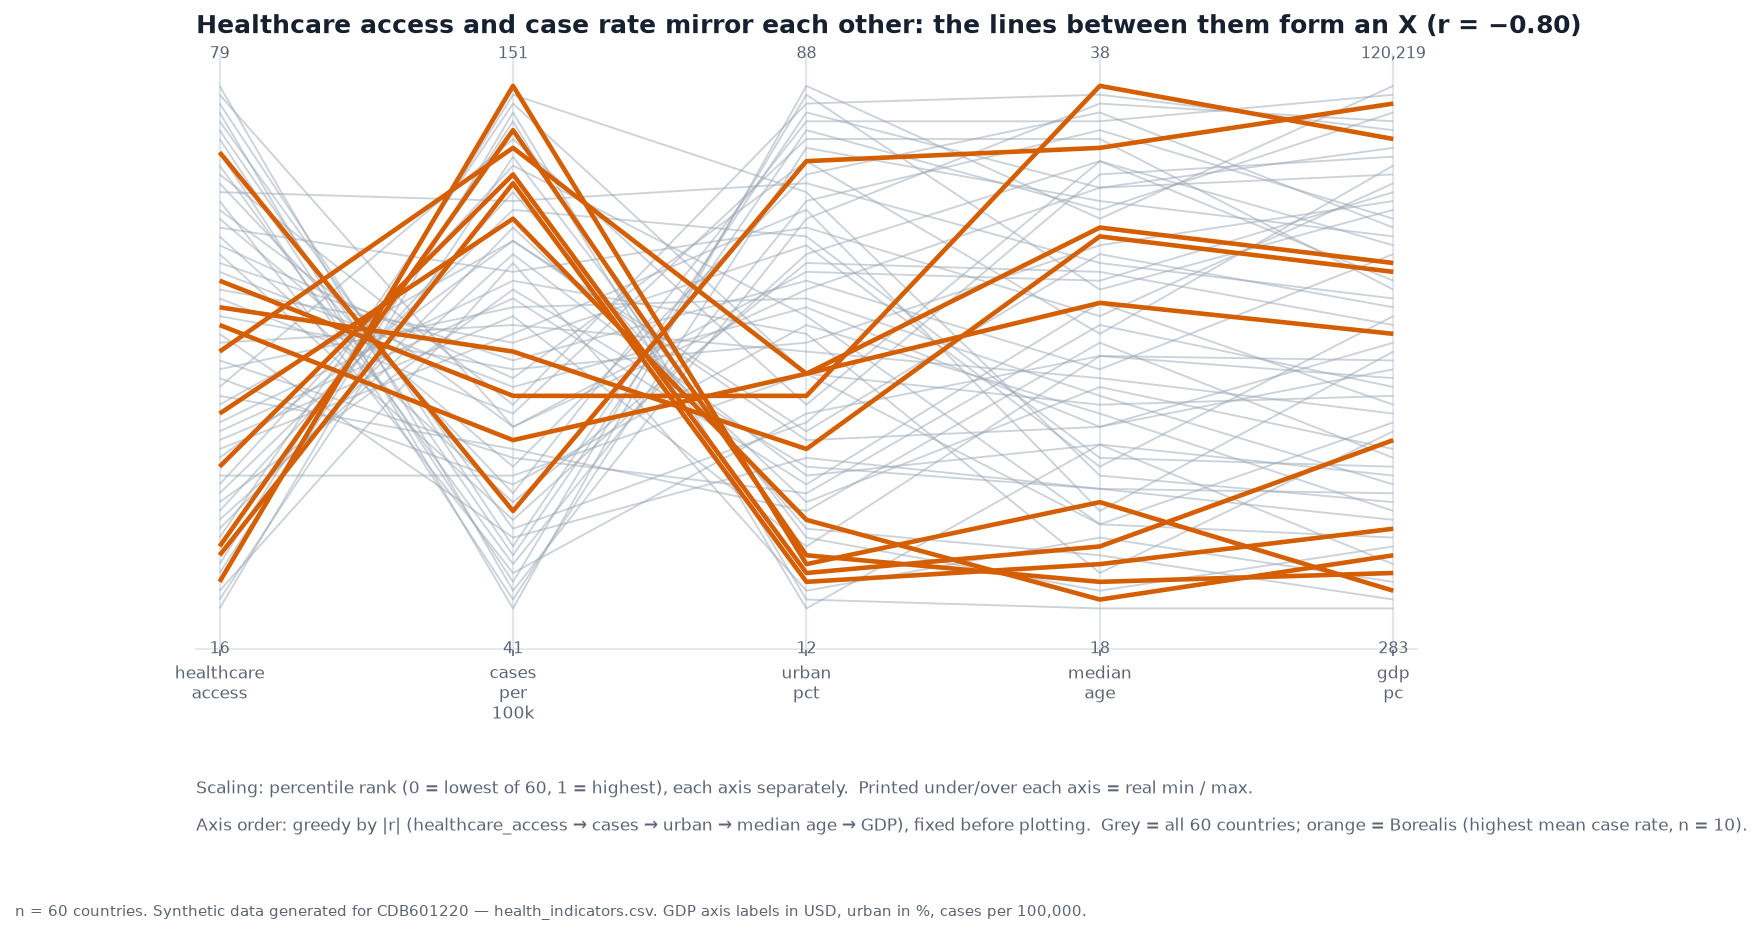

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 6.2))
fig.subplots_adjust(bottom=0.24)
mask = (hi.region == brush).to_numpy()
g.pcp(ax, hi, order, how="rank", highlight=mask, lw_bg=0.9, alpha_bg=0.5, lw_hl=2.2)

ax.set_title("Healthcare access and case rate mirror each other: the lines between them form an X (r = −0.80)", loc="left")
fig.text(0.125, 0.085, "Scaling: percentile rank (0 = lowest of 60, 1 = highest), each axis separately.  "
        "Printed under/over each axis = real min / max.", fontsize=8, color=PAL["ink_soft"])
fig.text(0.125, 0.045, "Axis order: greedy by |r| (healthcare_access → cases → urban → median age → GDP), "
        "fixed before plotting.  Grey = all 60 countries; orange = " + brush + " (highest mean case rate, n = %d)." % mask.sum(),
        fontsize=8, color=PAL["ink_soft"])
g.save_fig(fig, FIG + "partD_pcp.png",
           note="n = 60 countries. Synthetic data generated for CDB601220 — health_indicators.csv. "
                "GDP axis labels in USD, urban in %, cases per 100,000.")
plt.show()

In [5]:
# adjacent-pair evidence for the two relationships I name below
for a, b in zip(order[:-1], order[1:]):
    print(f"{a:18s} – {b:18s}  r = {R.loc[a,b]:+.3f}")
# does a high-access country also sit high on urban and age AND low on cases? count the full "profile"
rk = g.scale_frame(hi, NUM, "rank")
prof = (rk.healthcare_access > .5) & (rk.cases_per_100k < .5) & (rk.urban_pct > .5) & (rk.median_age > .5)
print(f"\n{prof.sum()} of 60 countries are above-median on access, urban, age AND below-median on cases")
print(f"…and {((rk.healthcare_access<.5)&(rk.cases_per_100k>.5)&(rk.urban_pct<.5)&(rk.median_age<.5)).sum()} sit in the opposite corner on all four")
b = hi[mask]
print(f"brushed {brush}: mean rank on access {rk[mask].healthcare_access.mean():.2f}, cases {rk[mask].cases_per_100k.mean():.2f}, urban {rk[mask].urban_pct.mean():.2f}")
print(f"within {brush}: r(access, cases) = {b.healthcare_access.corr(b.cases_per_100k):+.2f}, r(urban, age) = {b.urban_pct.corr(b.median_age):+.2f}")
print(f"{brush} countries in the opposite corner on all four: {int((~prof & (rk.healthcare_access<.5)&(rk.cases_per_100k>.5)&(rk.urban_pct<.5)&(rk.median_age<.5))[mask].sum())} of {mask.sum()}")

healthcare_access  – cases_per_100k      r = -0.799
cases_per_100k     – urban_pct           r = -0.619
urban_pct          – median_age          r = +0.644
median_age         – gdp_pc              r = +0.281

18 of 60 countries are above-median on access, urban, age AND below-median on cases
…and 16 sit in the opposite corner on all four
brushed Borealis: mean rank on access 0.41, cases 0.67, urban 0.31
within Borealis: r(access, cases) = -0.87, r(urban, age) = +0.87
Borealis countries in the opposite corner on all four: 5 of 10


## Two relationships you can actually see

1. **Healthcare access ↔ case rate (adjacent axes 1–2): strongly negative, r = −0.799.** Lines between the first two axes cross in an X — high-access countries
   run down to low case rates, low-access countries up to high ones. The brushed region (Borealis, highest mean case rate) shows it too: within its 10 countries r = −0.87, and its orange lines mostly climb from the lower half of axis 1 to the upper half of axis 2.
2. **Urban share ↔ median age (adjacent axes 3–4): strongly positive, r = +0.644.** Lines between them run nearly parallel (few crossings): countries
   that are more urban are also older. Case rate → urban (axes 2–3, r = −0.619) crosses again, closing the chain.

**What a pairwise scatter matrix would not have shown:** the full *profile* of a country in one line — the printed counts
show 18 of the 30 above-median-access countries are *simultaneously* above-median on urban share and age and below-median on cases, and 16 countries sit in the opposite corner on all four at once (5 of the 10 brushed Borealis countries are among them). 
A SPLOM shows ten separate pairs; the polyline shows that these are one profile, not four coincidences. (Caveat: that is 34 of 60 countries in the two corners, so about 43% sit in neither — the pattern is strong, not deterministic.)